# Базовая Logistic Regression

Задание № 7. Обучение выполняется только на train, оценка только на validation. Test не преобразуется и не оценивается.

In [1]:
from hashlib import sha256
from io import BytesIO
from pathlib import Path
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

root = Path(".") if Path("manage.py").is_file() else Path("..")
sys.path.insert(0, str(root))
from ml.baseline import MODEL_PATH, evaluate_baseline, load_partitions, predict_sms, train_baseline
from ml.preprocessing import normalize_sms

input_files = [root / "data/processed/sms_clean.csv", root / "data/processed/sms_split.json"]
input_hashes = [sha256(path.read_bytes()).digest() for path in input_files]
train, validation = load_partitions()
assert len(train) == 3594 and len(validation) == 770
assert set(train.id).isdisjoint(validation.id)
display(pd.DataFrame({"Выборка": ["train", "validation"], "SMS": [len(train), len(validation)],
                      "Spam": [int(train.label.sum()), int(validation.label.sum())]}))

,Выборка,SMS,Spam
0,train,3594,433
1,validation,770,92


## Обучение и метрики

LogisticRegression использует class_weight='balanced', max_iter=1000 и random_state=42. Нормализация включена в существующий пайплайн признаков.

In [2]:
model = train_baseline(train)
metrics, matrix, results = evaluate_baseline(model, validation)
display(pd.DataFrame({"Метрика": list(metrics), "Значение": list(metrics.values())}))
tn, fp, fn, tp = matrix.ravel()
display(pd.DataFrame({"Вид": ["TN", "FP", "FN", "TP"], "Количество": [tn, fp, fn, tp]}))

,Метрика,Значение
0,accuracy,0.980519
1,precision,0.905263
2,recall,0.934783
3,f1,0.919786


,Вид,Количество
0,TN,669
1,FP,9
2,FN,6
3,TP,86


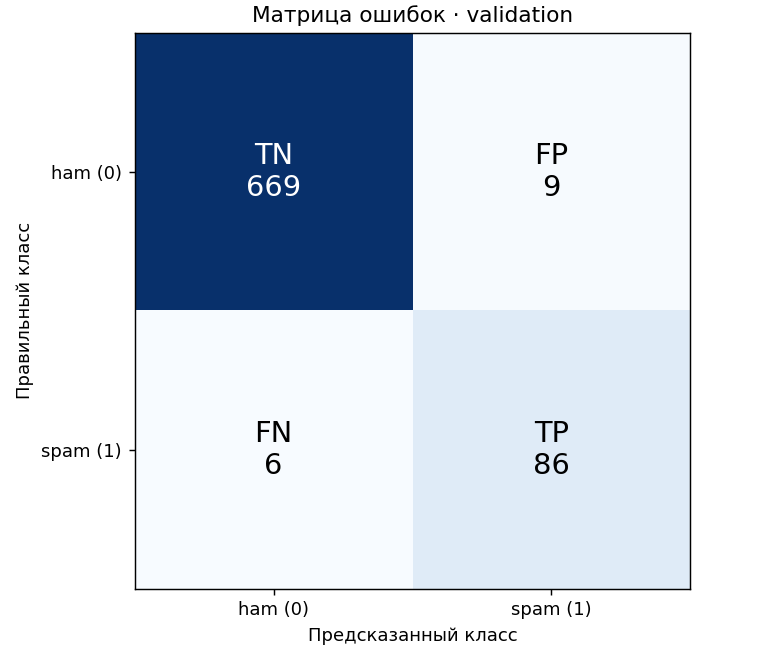

In [3]:
fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
ax.imshow(matrix, cmap="Blues")
for row in range(2):
    for column in range(2):
        name = [["TN", "FP"], ["FN", "TP"]][row][column]
        ax.text(column, row, f"{name}\n{matrix[row, column]}", ha="center", va="center",
                color="white" if matrix[row, column] > matrix.max() / 2 else "black", fontsize=16)
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["ham (0)", "spam (1)"],
       yticklabels=["ham (0)", "spam (1)"], xlabel="Предсказанный класс",
       ylabel="Правильный класс", title="Матрица ошибок · validation")
image = BytesIO()
fig.savefig(image, format="png", dpi=130)
plt.close(fig)
display(Image(data=image.getvalue()))

## Анализ ошибок

Первые пять FN и пять FP в порядке validation. Объяснения являются гипотезами по содержанию текста.

In [4]:
reasons = {
    2004: "Реклама загрузок похожа на разговорное сообщение. Ссылка упомянута словами, явного URL в тексте нет.",
    4145: "Викторина про фильм сформулирована как обычный вопрос, без явной денежной суммы или URL.",
    3531: "Анонс продажи билетов похож на легитимное уведомление клуба.",
    3420: "Личная эмоциональная формулировка занимает почти весь текст; платная услуга указана только в конце.",
    4017: "Краткое уведомление о рингтоне похоже на сервисное сообщение, без явного призыва оплатить.",
    5487: "Числа и необычный формат с разделителями могут напоминать рекламный шаблон.",
    3045: "Обычное обсуждение счёта содержит денежную сумму и восклицание.",
    3408: "Заглавные буквы, числовые сокращения и восклицание похожи на признаки давления.",
    4400: "Длинный текст о переводе в другой вуз содержит слово transfer, попадающее в денежную группу словаря.",
    3228: "Цепочное личное сообщение содержит призыв переслать его, числа и восклицания.",
}
examples = []
for title, actual, predicted in [("FN", 1, 0), ("FP", 0, 1)]:
    errors = results.loc[(results.label == actual) & (results.predicted == predicted)].head(5).copy()
    errors["Возможная причина"] = errors.id.map(reasons)
    assert errors["Возможная причина"].notna().all()
    errors["Тип"] = title
    examples.append(errors)
    display(Markdown(f"### {title}"))
    with pd.option_context("display.max_colwidth", None):
        display(errors.rename(columns={"text_raw": "Исходный текст", "label": "Метка",
                                       "predicted": "Прогноз", "probability": "P(spam)"}))
examples = pd.concat(examples, ignore_index=True)

### FN

,id,Исходный текст,Метка,Прогноз,P(spam),Возможная причина,Тип
1921,2004,TheMob>Yo yo yo-Here comes a new selection of hot downloads for our members to get for FREE! Just click & open the next link sent to ur fone...,1,0,0.464111,"Реклама загрузок похожа на разговорное сообщение. Ссылка упомянута словами, явного URL в тексте нет.",FN
3870,4145,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send A, B or C)",1,0,0.099062,"Викторина про фильм сформулирована как обычный вопрос, без явной денежной суммы или URL.",FN
3315,3531,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. They're selling fast!",1,0,0.464091,Анонс продажи билетов похож на легитимное уведомление клуба.,FN
3215,3420,LIFE has never been this much fun and great until you came in. You made it truly special for me. I won't forget you! enjoy @ one gbp/sms,1,0,0.263818,Личная эмоциональная формулировка занимает почти весь текст; платная услуга указана только в конце.,FN
3754,4017,You will be receiving this week's Triple Echo ringtone shortly. Enjoy it!,1,0,0.211170,"Краткое уведомление о рингтоне похоже на сервисное сообщение, без явного призыва оплатить.",FN


### FP

,id,Исходный текст,Метка,Прогноз,P(spam),Возможная причина,Тип
5057,5487,", , and picking them up from various points | going 2 yeovil | and they will do the motor project 4 3 hours | and then u take them home. || 12 2 5.30 max. || Very easy",0,1,0.576881,Числа и необычный формат с разделителями могут напоминать рекламный шаблон.,FP
2877,3045,Your bill at 3 is £33.65 so thats not bad!,0,1,0.677034,Обычное обсуждение счёта содержит денежную сумму и восклицание.,FP
3205,3408,"""HEY DAS COOL... IKNOW ALL 2 WELLDA PERIL OF STUDENTFINANCIAL CRISIS!SPK 2 U L8R.""",0,1,0.539267,"Заглавные буквы, числовые сокращения и восклицание похожи на признаки давления.",FP
4094,4400,"Can you tell Shola to please go to college of medicine and visit the academic department, tell the academic secretary what the current situation is and ask if she can transfer there. She should ask someone to check Sagamu for the same thing and lautech. Its vital she completes her medical education in Nigeria. Its less expensive much less expensive. Unless she will be getting citizen rates in new zealand.",0,1,0.731899,"Длинный текст о переводе в другой вуз содержит слово transfer, попадающее в денежную группу словаря.",FP
3043,3228,"Rose for red,red for blood,blood for heart,heart for u. But u for me.... Send tis to all ur friends.. Including me.. If u like me.. If u get back, 1-u r poor in relation! 2-u need some 1 to support 3-u r frnd 2 many 4-some1 luvs u 5+- some1 is praying god to marry u.:-) try it....",0,1,0.762890,"Цепочное личное сообщение содержит призыв переслать его, числа и восклицания.",FP


## Сохранение полного Pipeline

In [5]:
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(model, MODEL_PATH)
print(f"Размер файла модели: {MODEL_PATH.stat().st_size} байт")

Размер файла модели: 1522771 байт


## Повторная загрузка и проверка

In [6]:
restored = joblib.load(MODEL_PATH)
np.testing.assert_array_equal(model.predict(validation.text_raw), restored.predict(validation.text_raw))
np.testing.assert_array_equal(model.predict_proba(validation.text_raw), restored.predict_proba(validation.text_raw))
probabilities = restored.predict_proba(validation.text_raw)
assert probabilities.shape == (770, 2)
assert np.isfinite(probabilities).all()
assert ((probabilities >= 0) & (probabilities <= 1)).all()
np.testing.assert_allclose(probabilities.sum(axis=1), 1)
assert input_hashes == [sha256(path.read_bytes()).digest() for path in input_files]
print("Предсказания и вероятности полностью совпадают. CSV и разбиение не изменились.")

Предсказания и вероятности полностью совпадают. CSV и разбиение не изменились.


## Новые английские SMS

Искусственные демонстрационные примеры отсутствуют в train. Их прогнозы показывают работу функции, но не служат дополнительной оценкой качества.

In [7]:
new_texts = [
    "The astronomy club moved our telescope session to Friday evening.",
    "Your parcel is waiting. Confirm your card password at https://parcel-check.example now!",
    "Please bring the blue notebook when we meet for soup tomorrow.",
]
train_clean = set(train.text_raw.map(normalize_sms))
assert all(normalize_sms(text) not in train_clean for text in new_texts)
demo = pd.DataFrame([{"text": text, **predict_sms(text)} for text in new_texts])
with pd.option_context("display.max_colwidth", None):
    display(demo)

,text,label,probability
0,The astronomy club moved our telescope session to Friday evening.,0,0.045389
1,Your parcel is waiting. Confirm your card password at https://parcel-check.example now!,1,0.922755
2,Please bring the blue notebook when we meet for soup tomorrow.,0,0.033373


In [8]:
report = f"""# Первая базовая модель SMS

Обучена LogisticRegression с class_weight='balanced', max_iter=1000, random_state=42. В единый sklearn Pipeline включены существующий create_feature_pipeline() и классификатор. Нормализация выполняется внутри извлечения признаков один раз за вызов предсказания.

Использовано сохранённое разбиение задания № 6. Train содержит {len(train)} SMS (3161 ham, 433 spam), validation — {len(validation)} (678 ham, 92 spam). Test не преобразуется и не оценивается. Параметры и порог не подбирались.

## Результаты validation

| Метрика | Значение |
|---|---:|
| Accuracy | {metrics['accuracy']:.6f} |
| Precision spam | {metrics['precision']:.6f} |
| Recall spam | {metrics['recall']:.6f} |
| F1 spam | {metrics['f1']:.6f} |

| Правильный класс | Прогноз ham | Прогноз spam |
|---|---:|---:|
| ham | TN = {tn} | FP = {fp} |
| spam | FN = {fn} | TP = {tp} |

Всего ошибок — {fp + fn}. Ниже первые пять ошибок каждого типа в порядке validation. Возможные причины являются гипотезами по тексту.

## Примеры ошибок
"""
for row in examples.to_dict("records"):
    report += (f"\n### {row['Тип']} · id {row['id']}\n\n"
               f"> {row['text_raw']}\n\n"
               f"Правильная метка {row['label']}, прогноз {row['predicted']}, "
               f"вероятность spam {row['probability']:.6f}.\n\n"
               f"{row['Возможная причина']}\n")
report += """
## Запуск и использование

Из корня проекта с активированным окружением выполните:

    python -m ml.baseline
    python -m pytest -q

Эксперимент с графиком и разбором ошибок находится в notebooks/02_baseline_sms.ipynb. Выполните все ячейки по порядку, выбрав ядро виртуального окружения проекта. Если локальные данные отсутствуют, восстановите их по инструкции docs/06_feature_extraction.md.

Полный Pipeline сохраняется в ml/artifacts/sms_baseline.joblib. Пример использования после обучения:

    from ml.baseline import predict_sms

    result = predict_sms("Please bring the blue notebook tomorrow.")
    print(result["label"], result["probability"])

Функция загружает локальную модель. probability всегда означает вероятность spam (1), включая случаи, когда label равен 0. Передавать следует исходный текст, поскольку нормализация включена в Pipeline.

Предсказания и вероятности до и после сохранения полностью совпали на validation. Проверены диапазон вероятностей и сумма вероятностей классов. Новые демонстрационные SMS отсутствуют в train. Словари и IDF формируются при fit только на train. CSV и файл разбиения после эксперимента не изменились.

## Ограничения

Spam в исходном UCI-корпусе не всегда означает мошенничество. Метрики характеризуют различение ham и spam на английском языке и не доказывают качество обнаружения именно мошенничества. Русские и казахские SMS здесь не оцениваются.
"""
(root / "docs/07_baseline_model.md").write_text(report, encoding="utf-8")
print("Отчёт сохранён в docs/07_baseline_model.md")

Отчёт сохранён в docs/07_baseline_model.md
